# Modelos Matemáticos y Estadísticos Clásicos
## Diplomado en Data Science 2026

---

## Clase 28 — Cierre del Módulo


### Objetivos

Repasar la mayor cantidad de contenidos de las 27 clases anteriores, determinando oportunidades a partir de un set de datos.

## Ejercicio Práctico


Una red de bicicletas compartidas llamada **CityBike** quiere entender mejor el comportamiento de sus usuarios y tomar decisiones sobre operación, campañas e incentivos.

A lo largo de esta clase trabajaremos con un mismo caso para repasar distintas herramientas estadísticas:

- Probabilidad e inferencia
- A/B Testing
- Regresión lineal
- Regresión logística
- Regresión de Poisson
- Series de tiempo / ARIMA

> **Objetivo de la clase:** no solo ejecutar modelos, sino aprender a reconocer **qué herramienta estadística corresponde a cada pregunta de negocio**.

---

### Pregunta guía

Antes de programar, pregúntate siempre:

1. ¿Cuál es la pregunta que quiero responder?
2. ¿Cuál es mi variable objetivo?
3. ¿Qué tipo de variable es?
4. ¿Qué método parece razonable?
5. ¿Cómo voy a interpretar el resultado?

## 0. Mapa de decisiones

| Pregunta | Variable objetivo | Herramienta posible |
|---|---|---|
| ¿Existen diferencias entre dos grupos? | Media o proporción | Inferencia / A/B Testing |
| ¿Cuánto durará un viaje? | Continua | Regresión lineal |
| ¿Un usuario realizará un viaje? | Binaria | Logit |
| ¿Cuántos viajes realizará? | Conteo | Poisson |
| ¿Cuántos viajes habrá en los próximos días? | Serie temporal | ARIMA |

Durante la clase volveremos a este mapa varias veces.



## Descripción del Problema

### De que trata este problema

**CityBike** es un sistema de bicicletas compartidas que opera en una gran ciudad y registra información sobre el comportamiento de sus usuarios, las condiciones del día y el uso del servicio.

### Dataset 1: `citybike_usuarios_dia`

Este dataset contiene información a nivel **usuario-día**.

Cada fila representa la observación de un usuario en una fecha determinada e incluye:

- características del usuario;
- información sobre su historial de uso;
- condiciones climáticas y de calendario;
- participación en una campaña experimental;
- número de viajes realizados;
- duración y distancia recorrida;
- satisfacción asociada al uso del servicio.

| Variable             | Descripción                                                                                                                     |
| -------------------- | ------------------------------------------------------------------------------------------------------------------------------- |
| `fecha`              | Fecha de observación correspondiente al registro usuario-día.                                                                   |
| `usuario_id`         | Identificador único del usuario.                                                                                                |
| `edad`               | Edad del usuario, en años.                                                                                                      |
| `tipo_usuario`       | Tipo de usuario: `Suscriptor` u `Ocasional`.                                                                                    |
| `zona`               | Zona de residencia del usuario.                                                                                                 |
| `antiguedad_meses`   | Número de meses desde que el usuario se registró en CityBike.                                                                   |
| `dia_semana`         | Día de la semana correspondiente a la fecha de observación.                                                                     |
| `fin_semana`         | Indicador binario: vale 1 si la fecha corresponde a sábado o domingo y 0 en caso contrario.                                     |
| `feriado`            | Indicador binario: vale 1 si la fecha corresponde a un feriado y 0 en caso contrario.                                           |
| `temperatura_c`      | Temperatura registrada durante el día, medida en grados Celsius.                                                                |
| `lluvia_mm`          | Precipitación registrada durante el día, medida en milímetros.                                                                  |
| `viajes_prev_30d`    | Número de viajes realizados por el usuario durante los 30 días anteriores.                                                      |
| `minutos_prev_30d`   | Minutos totales de uso acumulados por el usuario durante los 30 días anteriores.                                                |
| `grupo_ab`           | Grupo asignado en el experimento: `Tratamiento`, `Control` o `No_expuesto`.                                                     |
| `incentivo`          | Indicador binario: vale 1 si el usuario recibió el incentivo del experimento y 0 en caso contrario.                             |
| `uso_app`            | Indicador binario: vale 1 si el usuario utiliza la aplicación móvil y 0 en caso contrario.                                      |
| `hora_peak`          | Indicador binario asociado a períodos de alta demanda.                                                                          |
| `realizo_viaje`      | Indicador binario: vale 1 si el usuario realizó al menos un viaje durante el día y 0 en caso contrario.                         |
| `n_viajes_dia`       | Número total de viajes realizados por el usuario durante el día.                                                                |
| `distancia_total_km` | Distancia total recorrida por el usuario durante el día, medida en kilómetros.                                                  |
| `duracion_total_min` | Duración total de los viajes realizados por el usuario durante el día, medida en minutos.                                       |
| `satisfaccion`       | Evaluación de satisfacción del usuario en escala de 1 a 5. Solo está disponible para usuarios que realizaron al menos un viaje. |


## Dataset 2: `citybike_serie_diaria`

Este dataset contiene información agregada a nivel **día**.

Cada fila representa una fecha y resume el comportamiento global del sistema CityBike durante esa jornada, incluyendo:

- cantidad de usuarios observados;
- número total de viajes;
- número de usuarios que realizaron al menos un viaje;
- distancia y duración total de uso;
- condiciones climáticas promedio;
- tasa diaria de uso del servicio.

| Variable                 | Descripción                                                                            |
| ------------------------ | -------------------------------------------------------------------------------------- |
| `fecha`                  | Fecha correspondiente a la observación diaria.                                         |
| `usuarios_observados`    | Número de usuarios distintos observados durante el día.                                |
| `total_viajes`           | Número total de viajes realizados durante el día.                                      |
| `usuarios_con_viaje`     | Número de usuarios que realizaron al menos un viaje durante el día.                    |
| `distancia_total_km`     | Distancia total recorrida por todos los usuarios durante el día, medida en kilómetros. |
| `minutos_totales`        | Suma de los minutos de viaje realizados por todos los usuarios durante el día.         |
| `temperatura_promedio_c` | Temperatura promedio registrada durante el día, medida en grados Celsius.              |
| `lluvia_total_mm`        | Precipitación total registrada durante el día, medida en milímetros.                   |
| `tasa_uso`               | Proporción de usuarios observados que realizaron al menos un viaje durante el día.     |


## 1. Librerías y carga de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

from sklearn.metrics import RocCurveDisplay,  classification_report, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

plt.rcParams["figure.figsize"] = (10, 5)


In [ ]:
# Datos a nivel usuario-día
url_usuarios = "https://docs.google.com/spreadsheets/d/1jvhmJqO-TbtyZrqJI5XdiNkLM51FcNnZziq8HIC5oOE/export?format=csv"

citybike = pd.read_csv(url_usuarios, parse_dates=["fecha"])

print("citybike:", citybike.shape)

citybike: (300000, 22)


In [ ]:
# Serie agregada por día
url_serie = "https://docs.google.com/spreadsheets/d/145W6_H1vD_nnwNvDi-Fju7071NUumpnD4Kr7mSFosnQ/export?format=csv"

serie_diaria = pd.read_csv(url_serie, parse_dates=["fecha"])

print("serie_diaria:", serie_diaria.shape)


serie_diaria: (546, 9)


### Inspección inicial

Antes de modelar, entendamos qué tenemos.

**Preguntas:**
- ¿Cuál es la unidad de observación de `citybike`?
- ¿Qué variables parecen continuas, binarias, categóricas y de conteo?
- ¿Existen valores nulos? ¿Son necesariamente errores?



In [ ]:
display(citybike.head())
display(citybike.sample(5, random_state=42))

citybike.info()


,fecha,usuario_id,edad,tipo_usuario,zona,antiguedad_meses,dia_semana,fin_semana,feriado,temperatura_c,lluvia_mm,viajes_prev_30d,minutos_prev_30d,grupo_ab,incentivo,uso_app,hora_peak,realizo_viaje,n_viajes_dia,distancia_total_km,duracion_total_min,satisfaccion
0,2025-01-01,13,42,Suscriptor,Poniente,15,Miércoles,0,1,30.5000,0.0000,21,373.1000,No_expuesto,0,0,0,1,2,15.1600,75.9000,4.0000
1,2025-01-01,53,44,Suscriptor,Sur,22,Miércoles,0,1,28.4000,0.0000,26,717.2000,No_expuesto,0,1,1,0,0,0.0000,0.0000,NaN
2,2025-01-01,84,37,Suscriptor,Oriente,17,Miércoles,0,1,26.2000,0.0000,13,162.1000,No_expuesto,0,1,0,1,4,9.5700,48.1000,4.0000
3,2025-01-01,90,23,Ocasional,Centro,9,Miércoles,0,1,22.4000,0.0000,6,165.6000,No_expuesto,0,0,0,1,1,1.0400,11.9000,4.0000
4,2025-01-01,98,43,Suscriptor,Norte,55,Miércoles,0,1,25.1000,0.0000,27,"1,113.2000",No_expuesto,0,0,1,0,0,0.0000,0.0000,NaN


,fecha,usuario_id,edad,tipo_usuario,zona,antiguedad_meses,dia_semana,fin_semana,feriado,temperatura_c,lluvia_mm,viajes_prev_30d,minutos_prev_30d,grupo_ab,incentivo,uso_app,hora_peak,realizo_viaje,n_viajes_dia,distancia_total_km,duracion_total_min,satisfaccion
4941,2025-01-10,2991,44,Suscriptor,Norte,25,Viernes,0,0,28.7000,0.0000,18,250.4000,No_expuesto,0,1,1,0,0,0.0000,0.0000,NaN
51775,2025-04-05,9476,42,Suscriptor,Poniente,33,Sábado,1,0,26.1000,0.0000,25,170.8000,No_expuesto,0,1,1,1,3,4.1900,19.0000,5.0000
115253,2025-07-29,18374,36,Suscriptor,Norte,23,Martes,0,0,8.9000,0.0000,17,359.4000,No_expuesto,0,1,0,1,1,4.9400,29.5000,5.0000
299321,2026-06-29,21516,44,Suscriptor,Norte,19,Lunes,0,0,5.8000,0.0000,17,335.8000,No_expuesto,0,0,0,1,1,4.5600,22.3000,3.0000
173570,2025-11-12,22120,34,Ocasional,Sur,18,Miércoles,0,0,23.7000,0.0000,6,28.5000,No_expuesto,0,0,1,0,0,0.0000,0.0000,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 22 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   fecha               300000 non-null  datetime64[ns]
 1   usuario_id          300000 non-null  int64         
 2   edad                300000 non-null  int64         
 3   tipo_usuario        300000 non-null  object        
 4   zona                300000 non-null  object        
 5   antiguedad_meses    300000 non-null  int64         
 6   dia_semana          300000 non-null  object        
 7   fin_semana          300000 non-null  int64         
 8   feriado             300000 non-null  int64         
 9   temperatura_c       300000 non-null  float64       
 10  lluvia_mm           300000 non-null  float64       
 11  viajes_prev_30d     300000 non-null  int64         
 12  minutos_prev_30d    300000 non-null  float64       
 13  grupo_ab            300000 no

In [ ]:
citybike.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha,300000,NaN,NaN,NaN,2025-09-30 11:56:58.848000,2025-01-01 00:00:00,2025-05-17 00:00:00,2025-09-30 00:00:00,2026-02-14 00:00:00,2026-06-30 00:00:00,NaN
usuario_id,"300,000.0000",NaN,NaN,NaN,"12,510.7852",1.0000,"6,261.0000","12,527.0000","18,738.0000","25,000.0000","7,211.0802"
edad,"300,000.0000",NaN,NaN,NaN,36.3207,18.0000,28.0000,36.0000,44.0000,72.0000,11.2637
tipo_usuario,300000,2,Suscriptor,204373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zona,300000,5,Centro,74129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
antiguedad_meses,"300,000.0000",NaN,NaN,NaN,23.7836,1.0000,14.0000,21.0000,31.0000,60.0000,13.1394
dia_semana,300000,7,Lunes,42965,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fin_semana,"300,000.0000",NaN,NaN,NaN,0.2854,0.0000,0.0000,0.0000,1.0000,1.0000,0.4516
feriado,"300,000.0000",NaN,NaN,NaN,0.0131,0.0000,0.0000,0.0000,0.0000,1.0000,0.1139
temperatura_c,"300,000.0000",NaN,NaN,NaN,18.5980,-3.8000,13.0000,18.9000,24.2000,41.0000,6.7867


In [ ]:
# Valores faltantes
(
    citybike.isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)


,0
satisfaccion,174977
fecha,0
edad,0
tipo_usuario,0
zona,0
usuario_id,0
antiguedad_meses,0
dia_semana,0
feriado,0
fin_semana,0


> 💬 **Discusión:** `satisfaccion` tiene valores faltantes.  
> ¿Es necesariamente un problema de calidad de datos? Revisa cuándo aparece `NaN`.


In [ ]:
pd.crosstab(
    citybike["realizo_viaje"],
    citybike["satisfaccion"].isna(),
    normalize="index"
)


satisfaccion,False,True
realizo_viaje,,
0,0.0000,1.0000
1,1.0000,0.0000


---

# 2. El Grupo ocacional vs suscriptor, ¿poseen las mismas probabilidades de uso?

Antes del experimento, hagamos una exploración sencilla.

Queremos comparar la probabilidad de realizar al menos un viaje según algunas características del usuario.

Recordemos que una probabilidad condicional puede estimarse empíricamente como una proporción:

$$
P(A\mid B) \approx \frac{\text{casos en que ocurre A y B}}{\text{casos en que ocurre B}}
$$


In [ ]:
# Probabilidad empírica global de realizar al menos un viaje
p_viaje = citybike["realizo_viaje"].mean()
print(p_viaje)

0.41674333333333335


In [ ]:
# Probabilidad condicional según tipo de usuario
prob_tipo = (
    citybike
    .groupby("tipo_usuario")["realizo_viaje"]
    .agg(["sum","count", "mean"])
    .rename(columns={"mean": "probabilidad_viaje"})
)

prob_tipo


,sum,count,probabilidad_viaje
tipo_usuario,,,
Ocasional,27686,95627,0.2895
Suscriptor,97337,204373,0.4763


### Pregunta

¿Observar una diferencia en las proporciones es suficiente para concluir que los grupos se comportan distinto en la población?

No necesariamente. Ahí aparece la **inferencia estadística**.

Tomemos como ejemplo Suscriptores versus usuarios Ocasionales y contrastemos sus proporciones.


In [ ]:
conteos = np.array([
    prob_tipo.loc["Suscriptor", "sum"],
    prob_tipo.loc["Ocasional", "sum"]
])

n = np.array([
    prob_tipo.loc["Suscriptor", "count"],
    prob_tipo.loc["Ocasional", "count"]
])

z_stat, p_value = proportions_ztest(conteos, n)

print(f"Estadístico z = {z_stat:.3f}")
print(f"p-value = {p_value:.5g}")


Estadístico z = 96.681
p-value = 0


> 💬 **Interpretación:** un p-value pequeño entrega evidencia contra la hipótesis de igualdad de proporciones.  
> Pero recuerda: **significancia estadística no implica causalidad**. Ser Suscriptor no fue asignado aleatoriamente.


---

# 3. A/B Testing: ¿funcionó el incentivo?

Durante marzo y abril de 2026, CityBike realizó un experimento con usuarios elegibles.

- **Control:** no recibió incentivo.
- **Tratamiento:** recibió un incentivo para utilizar el servicio.
- Resultado de interés: `realizo_viaje`.

### Hipótesis

$$
H_0: p_T = p_C
$$

$$
H_1: p_T \neq p_C
$$

Primero debemos identificar correctamente la muestra experimental.


In [ ]:
citybike["grupo_ab"].value_counts()


,count
grupo_ab,
No_expuesto,272337
Control,13885
Tratamiento,13778


>  **Ojo:** `No_expuesto` no es parte del experimento.  



> Comparar Tratamiento contra todos los demás usuarios sería un error.


In [ ]:
ab = citybike[
    citybike["grupo_ab"].isin(["Control", "Tratamiento"])
].copy()

print(ab.shape)
display(ab["grupo_ab"].value_counts())


(27663, 22)


,count
grupo_ab,
Control,13885
Tratamiento,13778


### 3.1 Comparación descriptiva

In [ ]:
resultado_ab = (
    ab.groupby("grupo_ab")["realizo_viaje"]
      .agg(n="count", viajes="sum", tasa_conversion="mean")
)

resultado_ab


,n,viajes,tasa_conversion
grupo_ab,,,
Control,13885,5466,0.3937
Tratamiento,13778,6349,0.4608


In [ ]:
p_trat = resultado_ab.loc["Tratamiento", "tasa_conversion"]
p_control = resultado_ab.loc["Control", "tasa_conversion"]

In [ ]:
# uplift real
print(p_trat - p_control)

0.06714485833359513


In [ ]:

# uplift relativo
print(p_trat / p_control - 1)

0.17056464653530345


### 3.2 Test de diferencia de proporciones

Ahora evaluamos si la diferencia observada es compatible con una fluctuación aleatoria.


In [ ]:
conteos = np.array([
    resultado_ab.loc["Tratamiento", "viajes"],
    resultado_ab.loc["Control", "viajes"]
])

nobs = np.array([
    resultado_ab.loc["Tratamiento", "n"],
    resultado_ab.loc["Control", "n"]
])

z_stat, p_value = proportions_ztest(conteos, nobs)

print(f"z = {z_stat:.3f}")
print(f"p-value = {p_value:.5g}")


z = 11.288
p-value = 1.5009e-29


In [ ]:
# Intervalo de confianza aproximado para la diferencia de proporciones
diff = p_trat - p_control
se = np.sqrt(
    p_trat * (1 - p_trat) / resultado_ab.loc["Tratamiento", "n"] +
    p_control * (1 - p_control) / resultado_ab.loc["Control", "n"]
)

z_975 = stats.norm.ppf(0.975)
li = diff - z_975 * se
ls = diff + z_975 * se


# Resultado!
print(f"Diferencia: {diff:.3%}")
print(f"IC 95%: [{li:.3%}, {ls:.3%}]")


Diferencia: 6.714%
IC 95%: [5.551%, 7.878%]


### Para discutir

1. ¿El experimento muestra una diferencia estadísticamente significativa?
2. ¿De qué magnitud es el efecto?
3. ¿Por qué acá podemos hablar de un efecto causal con más confianza que en la comparación Suscriptor/Ocasional?
4. ¿Qué información adicional pedirías antes de recomendar implementar el incentivo a toda la base?


---

# 4. ¿Qué explica la duración de los viajes?

Ahora la pregunta cambia.

> **Pregunta de negocio:** entre los usuarios que realizaron viajes, ¿qué factores están asociados con la duración total de uso durante el día?

La variable objetivo `duracion_total_min` es **continua**, por lo que una regresión lineal es un punto de partida razonable.

Trabajaremos solo con observaciones donde ocurrió al menos un viaje.


In [ ]:
viajeros = citybike[citybike["realizo_viaje"] == 1].copy()

viajeros[[
    "duracion_total_min",
    "distancia_total_km",
    "lluvia_mm",
    "hora_peak",
    "tipo_usuario"
]].describe()


,duracion_total_min,distancia_total_km,lluvia_mm,hora_peak
count,"125,023.0000","125,023.0000","125,023.0000","125,023.0000"
mean,29.6520,5.6225,0.6062,0.3576
std,17.5171,4.0004,2.2358,0.4793
min,0.0000,0.0400,0.0000,0.0000
25%,17.6000,2.7900,0.0000,0.0000
50%,26.3000,4.7000,0.0000,0.0000
75%,38.0000,7.4200,0.0000,1.0000
max,199.1000,48.7300,34.9000,1.0000


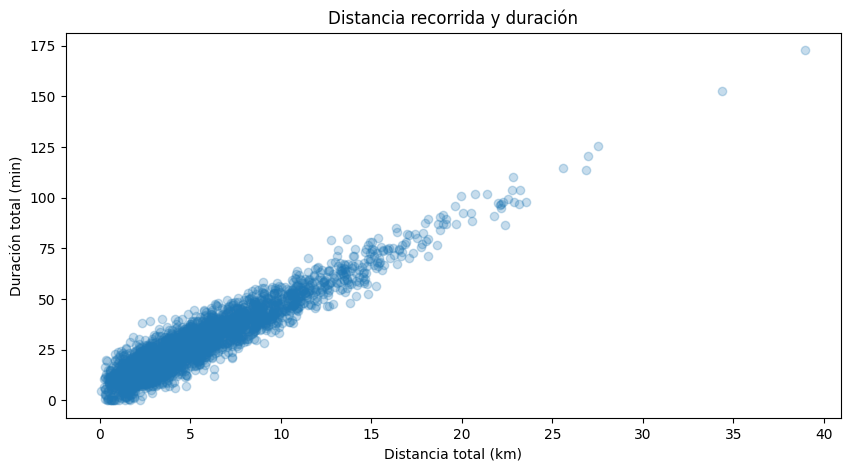

In [ ]:
muestra_plot = viajeros.sample(3000, random_state=42)

plt.scatter(
    muestra_plot["distancia_total_km"],
    muestra_plot["duracion_total_min"],
    alpha=0.25
)

plt.xlabel("Distancia total (km)")
plt.ylabel("Duración total (min)")
plt.title("Distancia recorrida y duración")
plt.show()


### 4.1 Modelo simple

Partamos con:

$$
duracion = \beta_0 + \beta_1 distancia + \varepsilon
$$


In [ ]:
modelo_simple = smf.ols(
    "duracion_total_min ~ distancia_total_km",
    data=viajeros
).fit()

print(modelo_simple.summary())


                            OLS Regression Results                            
Dep. Variable:     duracion_total_min   R-squared:                       0.895
Model:                            OLS   Adj. R-squared:                  0.895
Method:                 Least Squares   F-statistic:                 1.064e+06
Date:                Fri, 14 Aug 2026   Prob (F-statistic):               0.00
Time:                        00:30:29   Log-Likelihood:            -3.9454e+05
No. Observations:              125023   AIC:                         7.891e+05
Df Residuals:                  125021   BIC:                         7.891e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              6.3620      0

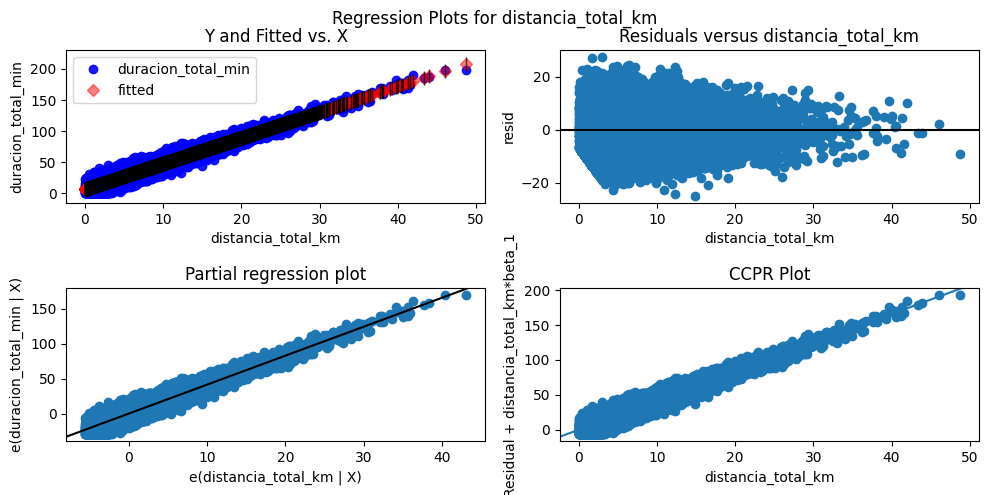

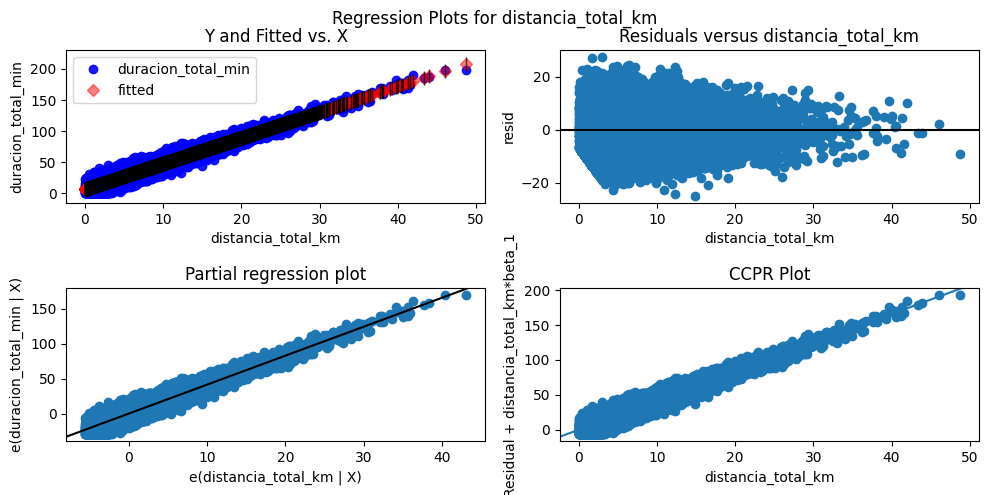

In [ ]:
sm.graphics.plot_regress_exog(modelo_simple, "distancia_total_km")

### Preguntas de interpretación

- ¿Qué significa el intercepto?
- ¿Cómo interpretarías el coeficiente de `distancia_total_km`?
- ¿Es estadísticamente significativo?
- ¿Qué porcentaje de la variabilidad explica el modelo?


### 4.2 Modelo múltiple

In [ ]:
formula_lineal = (
    "duracion_total_min ~ distancia_total_km + lluvia_mm + hora_peak "
    "+ C(tipo_usuario) + C(fin_semana)"
)

modelo_lineal = smf.ols(
    formula_lineal,
    data=viajeros
).fit()

print(modelo_lineal.summary())


                            OLS Regression Results                            
Dep. Variable:     duracion_total_min   R-squared:                       0.902
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                 2.310e+05
Date:                Fri, 14 Aug 2026   Prob (F-statistic):               0.00
Time:                        00:48:18   Log-Likelihood:            -3.8994e+05
No. Observations:              125023   AIC:                         7.799e+05
Df Residuals:                  125017   BIC:                         7.800e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

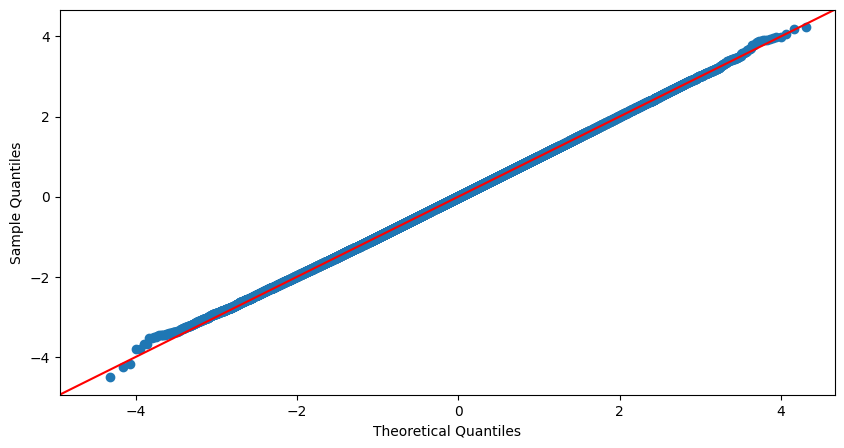

In [ ]:
sm.qqplot(modelo_lineal.resid, line = "45", fit = True)
plt.show()

In [ ]:
# sm.graphics.influence_plot(modelo_lineal)

---

# 5. ¿Quién realizará un viaje?

La pregunta vuelve a cambiar:

> **Pregunta de negocio:** ¿qué variables están asociadas con la probabilidad de que un usuario realice al menos un viaje durante el día?

Ahora la variable objetivo `realizo_viaje` toma valores **0/1**.

Una regresión lineal no es la herramienta más natural. Usaremos una **regresión logística**.


In [ ]:
print(citybike.realizo_viaje.mean())

0.41674333333333335


¿Cambia la probabilidad según algunas variables? ya lo vimos para tipo de usuario:

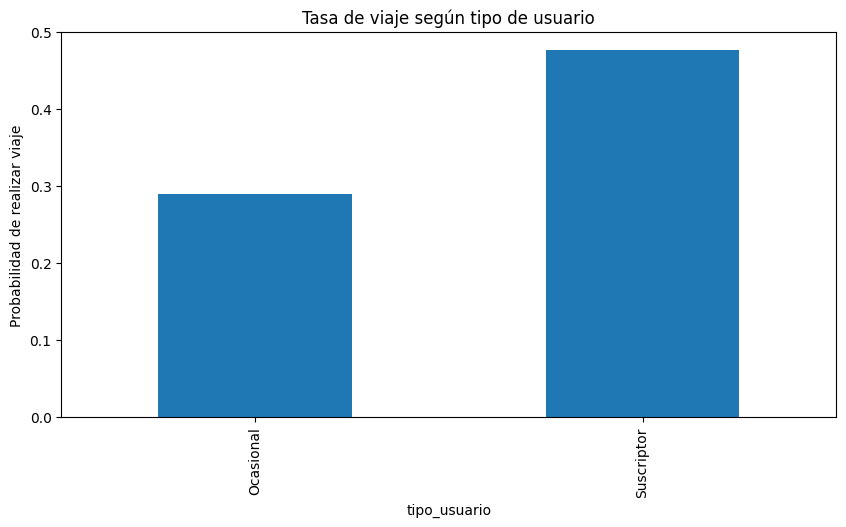

In [ ]:
(
    citybike
    .groupby("tipo_usuario")["realizo_viaje"]
    .mean()
    .plot(kind="bar")
)

plt.ylabel("Probabilidad de realizar viaje")
plt.title("Tasa de viaje según tipo de usuario")
plt.show()

También podemos hacer el ejercicio con variables continuas; una forma sencilla es poder verla por tramos:

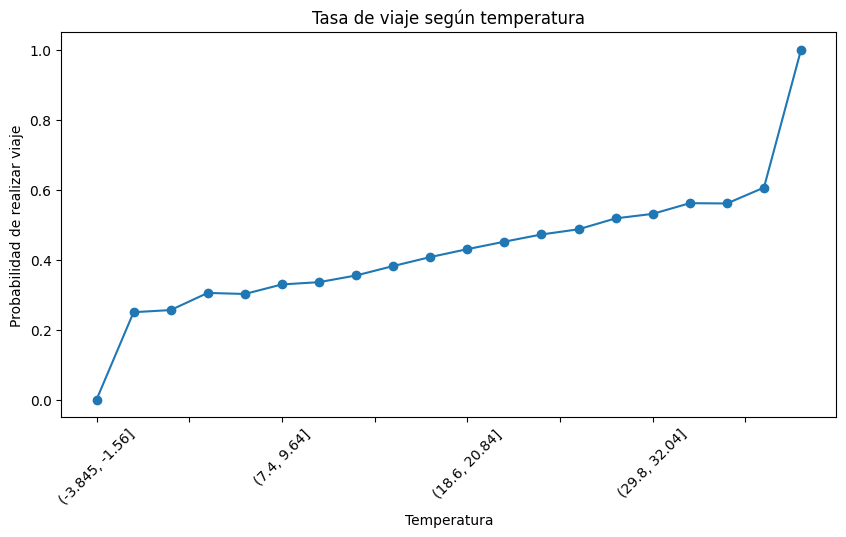

In [ ]:
citybike["grupo_temp"] = pd.cut(
    citybike["temperatura_c"],
    bins=20
)

temp_plot = (
    citybike
    .groupby("grupo_temp", observed=True)["realizo_viaje"]
    .mean()
)

temp_plot.plot(marker="o")

plt.ylabel("Probabilidad de realizar viaje")
plt.xlabel("Temperatura")
plt.title("Tasa de viaje según temperatura")
plt.xticks(rotation=45)
plt.show()

In [ ]:
logit_data = citybike.copy()


formula_logit = (
    "realizo_viaje ~ temperatura_c + lluvia_mm + np.log1p(viajes_prev_30d) "
    "+ incentivo + C(tipo_usuario) + C(fin_semana)"
)

modelo_logit = smf.logit(
    formula_logit,
    data=logit_data
).fit()

print(modelo_logit.summary())


Optimization terminated successfully.
         Current function value: 0.627548
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          realizo_viaje   No. Observations:               300000
Model:                          Logit   Df Residuals:                   299993
Method:                           MLE   Df Model:                            6
Date:                Fri, 14 Aug 2026   Pseudo R-squ.:                 0.07607
Time:                        01:09:06   Log-Likelihood:            -1.8826e+05
converged:                       True   LL-Null:                   -2.0377e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                        -3.3753      0.023   -143.738      0.

### Coeficientes versus Odds Ratios

Los coeficientes del Logit están expresados en **log-odds**.  
Muchas veces resulta más intuitivo exponentiarlos:

$$
OR = e^{\beta}
$$


In [ ]:
odds_ratios = pd.DataFrame({
    "coeficiente": modelo_logit.params,
    "odds_ratio": np.exp(modelo_logit.params),
    "p_value": modelo_logit.pvalues
})

odds_ratios


,coeficiente,odds_ratio,p_value
Intercept,-3.3753,0.0342,0.0000
C(tipo_usuario)[T.Suscriptor],0.4243,1.5285,0.0000
C(fin_semana)[T.1],-0.1626,0.8499,0.0000
temperatura_c,0.0388,1.0396,0.0000
lluvia_mm,-0.0916,0.9125,0.0000
np.log1p(viajes_prev_30d),0.8553,2.3521,0.0000
incentivo,0.2620,1.2995,0.0000


### Predicción de probabilidades

Veamos dos perfiles hipotéticos que solo difieren en el incentivo.


In [ ]:
perfil = pd.DataFrame({
    "temperatura_c": [20, 20],
    "lluvia_mm": [0, 0],
    "viajes_prev_30d": [5, 5],
    "incentivo": [0, 1],
    "tipo_usuario": ["Suscriptor", "Suscriptor"],
    "fin_semana": [0, 0]
})

perfil["probabilidad_estimada"] = modelo_logit.predict(perfil)
perfil


,temperatura_c,lluvia_mm,viajes_prev_30d,incentivo,tipo_usuario,fin_semana,probabilidad_estimada
0,20,0,5,0,Suscriptor,0,0.3447
1,20,0,5,1,Suscriptor,0,0.4060


### Desempeño del modelo


              precision    recall  f1-score   support

           0       0.67      0.78      0.72    174977
           1       0.60      0.46      0.52    125023

    accuracy                           0.65    300000
   macro avg       0.63      0.62      0.62    300000
weighted avg       0.64      0.65      0.64    300000



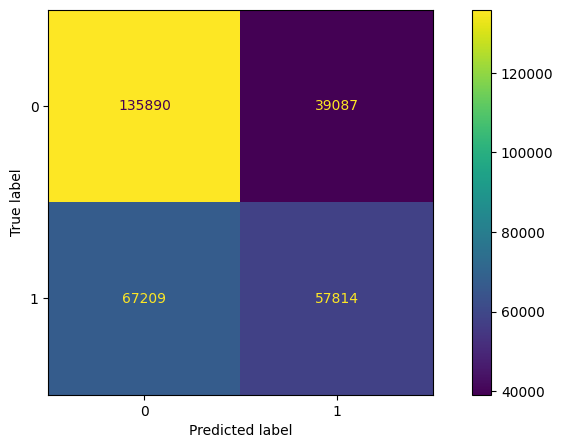

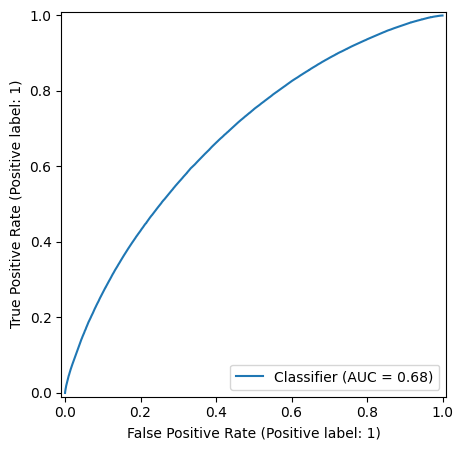

In [ ]:
# Probabilidades
logit_data["probabilidad"] = modelo_logit.predict(logit_data)

# Clasificación
logit_data["prediccion"] = (logit_data["probabilidad"] >= 0.5).astype(int)

# Métricas
print(classification_report(
    logit_data["realizo_viaje"],
    logit_data["prediccion"]
))

# Matriz
ConfusionMatrixDisplay.from_predictions(
    logit_data["realizo_viaje"],
    logit_data["prediccion"]
)

# ROC
RocCurveDisplay.from_predictions(
    logit_data["realizo_viaje"],
    logit_data["probabilidad"]
)

plt.show()

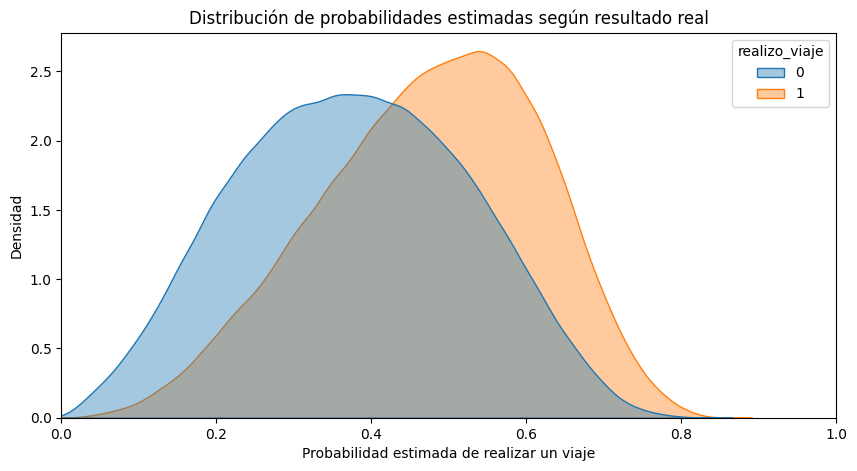

In [ ]:
sns.kdeplot(
    data=logit_data,
    x="probabilidad",
    hue="realizo_viaje",
    fill=True,
    common_norm=False,
    alpha=0.4
)

plt.xlabel("Probabilidad estimada de realizar un viaje")
plt.ylabel("Densidad")
plt.title("Distribución de probabilidades estimadas según resultado real")
plt.xlim(0, 1)

plt.show()

### Para discutir

- ¿Por qué un Logit es más apropiado que OLS para una variable binaria?
- ¿Cómo interpretarías el Odds Ratio asociado a la lluvia?
- ¿Es lo mismo un aumento de 20% en los *odds* que un aumento de 20 puntos porcentuales en probabilidad?
- ¿Qué precaución debemos tener al interpretar el coeficiente de `incentivo` usando datos fuera de la muestra experimental?


---

# 6. ¿Cuántos viajes realizará un usuario?

Hasta ahora modelamos **si** una persona viaja.

Ahora queremos responder:

> **¿Cuántos viajes realizará durante el día?**

La variable `n_viajes_dia` es un **conteo**:

- 0, 1, 2, 3, ...
- no puede tomar valores negativos.

Esto nos lleva naturalmente a un modelo de **Poisson**.


In [ ]:
citybike["n_viajes_dia"].value_counts().sort_index().head(12)


In [ ]:
print("Media:", citybike["n_viajes_dia"].mean())
print("Varianza:", citybike["n_viajes_dia"].var())


Para una Poisson ideal se cumple aproximadamente:

$$
E(Y) = Var(Y)
$$

En datos reales esta igualdad rara vez se cumple exactamente. Aun así, Poisson constituye un excelente punto de partida para variables de conteo.


In [ ]:
poisson_data = citybike.copy()

formula_poisson = (
    "n_viajes_dia ~ temperatura_c + lluvia_mm + np.log1p(viajes_prev_30d) "
    "+ incentivo + C(tipo_usuario) + C(fin_semana)"
)

modelo_poisson = smf.poisson(
    formula_poisson,
    data=poisson_data
).fit()

print(modelo_poisson.summary())


### Incidence Rate Ratios (IRR)

Al igual que en Logit, podemos exponentiar los coeficientes.

En Poisson:

$$
IRR = e^{\beta}
$$

Un IRR mayor que 1 se asocia con una tasa esperada de eventos mayor; uno menor que 1, con una tasa menor.


In [ ]:
irr = pd.DataFrame({
    "coeficiente": modelo_poisson.params,
    "IRR": np.exp(modelo_poisson.params),
    "p_value": modelo_poisson.pvalues
})

irr


Podemos realizar un gráfico de valores reales vs predichos. El problema es que la predicción puede ser un número real (pensando en que la tasa es real) y eso puede generar un gráfico que no se vea tanta relación entre ambos resultados

In [ ]:
poisson_data["predicho"] = modelo_poisson.predict(poisson_data)
poisson_data["predicho_redondeado"] = poisson_data["predicho"].round().astype(int)

real = poisson_data["n_viajes_dia"].value_counts(normalize=True)
pred = poisson_data["predicho_redondeado"].value_counts(normalize=True)

comparacion = pd.concat(
    [real, pred],
    axis=1,
    keys=["Real", "Predicho"]
).fillna(0).sort_index()

comparacion.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel("Número de viajes")
plt.ylabel("Proporción")
plt.title("Distribución real vs predicha")
plt.legend()
plt.show()

Pero otra forma de verlo es dividir la muestra en grupos (en muchos casos se les llama grupos de riesgo) que para efectos sencillos se´ria los deciles según el valor de la predicción. En concreto, dentro de este grupo se puede obtener la media de la predicción, así como la media del valor real; esta relación hace que sea mucho más "pareja" la comparación, ya que llevamos a la misma escala (la tasa por grupo) y se nota un mejor ajuste

In [ ]:
# Agrupamos usuarios según su número esperado de viajes
poisson_data["grupo_pred"] = pd.qcut(
    poisson_data["predicho"],
    q=10,
    duplicates="drop"
)

comparacion = (
    poisson_data
    .groupby("grupo_pred", observed=True)
    .agg(
        real=("n_viajes_dia", "mean"),
        predicho=("predicho", "mean")
    )
    .reset_index()
)

comparacion["grupo"] = range(1, len(comparacion) + 1)

comparacion.plot(
    x="grupo",
    y=["real", "predicho"],
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Grupo según cantidad esperada de viajes")
plt.ylabel("Número promedio de viajes")
plt.title("Viajes reales vs predichos")
plt.legend(["Real", "Predicho"])
plt.show()

### Una comparación importante

¿Por qué no modelar simplemente `n_viajes_dia` con una regresión lineal?

Piensa en:

- soporte de la variable;
- predicciones negativas;
- forma de la distribución;
- relación entre media y varianza.

La elección del modelo depende también de la **naturaleza de la variable objetivo**.


---

# 7. ¿cuántos viajes habrá en los próximos días?

Hasta ahora cada fila representaba un usuario-día.

Para planificación operacional necesitamos otra unidad de análisis:

> **un día completo de CityBike.**

Trabajaremos con `serie_diaria`, que ya contiene información agregada por fecha.


In [ ]:
display(serie_diaria.head())
display(serie_diaria.tail())


,fecha,usuarios_observados,total_viajes,usuarios_con_viaje,distancia_total_km,minutos_totales,temperatura_promedio_c,lluvia_total_mm,tasa_uso
0,2025-01-01,547,316,224,"1,151.1800","6,311.0000",26.0400,272.7,4.0950
1,2025-01-02,544,404,262,"1,566.1000","8,296.1000",26.2200,312.5,4.8160
2,2025-01-03,534,430,280,"1,546.9200","8,290.6000",26.2500,374.4,5.2430
3,2025-01-04,540,369,251,"1,373.0000","6,813.5000",26.1400,381.7,4.6480
4,2025-01-05,518,319,222,"1,312.5900","6,599.8000",26.2500,30.909.999.999.999.900,4.2860


,fecha,usuarios_observados,total_viajes,usuarios_con_viaje,distancia_total_km,minutos_totales,temperatura_promedio_c,lluvia_total_mm,tasa_uso
541,2026-06-26,536,231,165,876.6600,"4,834.1000",10.2400,966.9,3.0780
542,2026-06-27,541,233,180,991.7500,"5,101.7000",10.1100,873.6,3.3270
543,2026-06-28,546,209,168,834.3000,"4,244.5000",10.3000,954.6,3.0770
544,2026-06-29,543,253,194,968.0400,"5,332.8000",10.1500,960.7,3.5730
545,2026-06-30,588,244,192,929.1600,"5,212.6000",9.9300,1104.5,3.2650


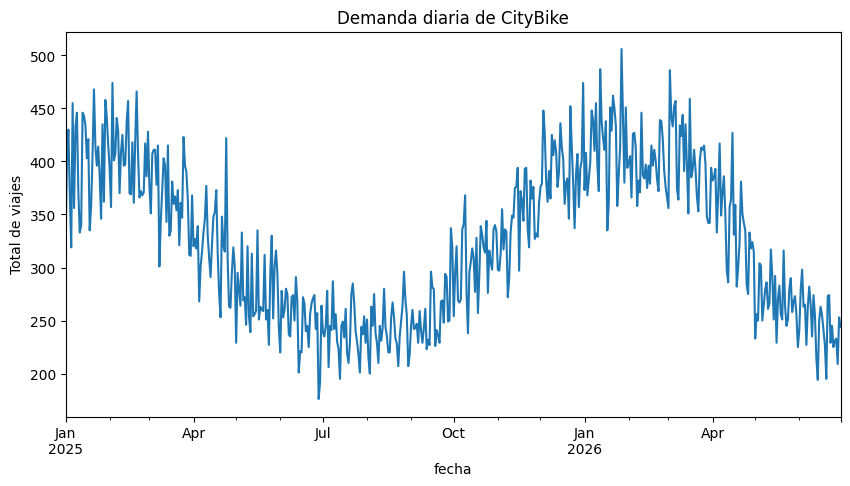

In [ ]:
serie = (
    serie_diaria
    .sort_values("fecha")
    .set_index("fecha")["total_viajes"]
)

serie.plot()
plt.ylabel("Total de viajes")
plt.title("Demanda diaria de CityBike")
plt.show()


### 7.1 Entrenamiento y validación temporal

En una serie de tiempo **no debemos separar train/test aleatoriamente**.

Usaremos los últimos 30 días como conjunto de validación.


In [ ]:
h = 30

train = serie.iloc[:-h]
test = serie.iloc[-h:]

print("Train:", train.index.min().date(), "→", train.index.max().date())
print("Test: ", test.index.min().date(), "→", test.index.max().date())


Train: 2025-01-01 → 2026-05-31
Test:  2026-06-01 → 2026-06-30


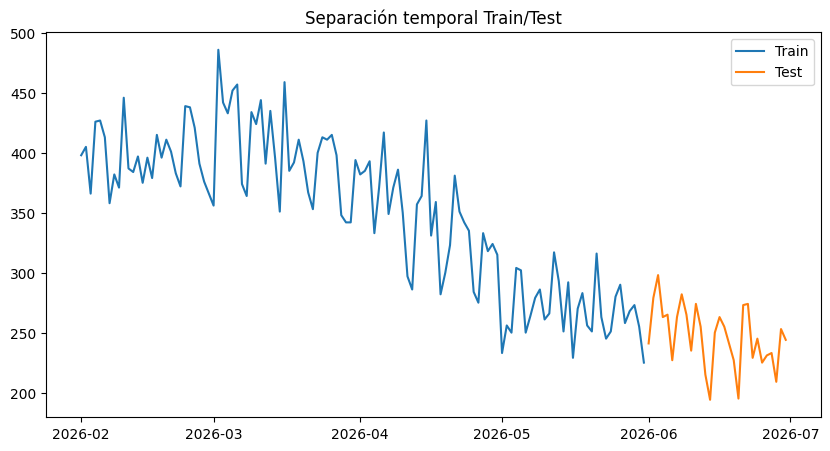

In [ ]:
plt.plot(train.index[-120:], train.iloc[-120:], label="Train")
plt.plot(test.index, test, label="Test")
plt.legend()
plt.title("Separación temporal Train/Test")
plt.show()


### 7.2 Autocorrelación

Las funciones ACF y PACF nos ayudan a explorar dependencia temporal.


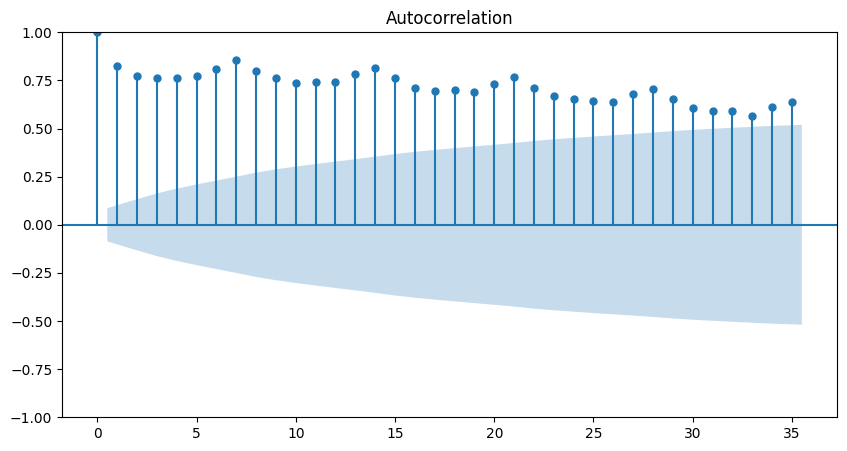

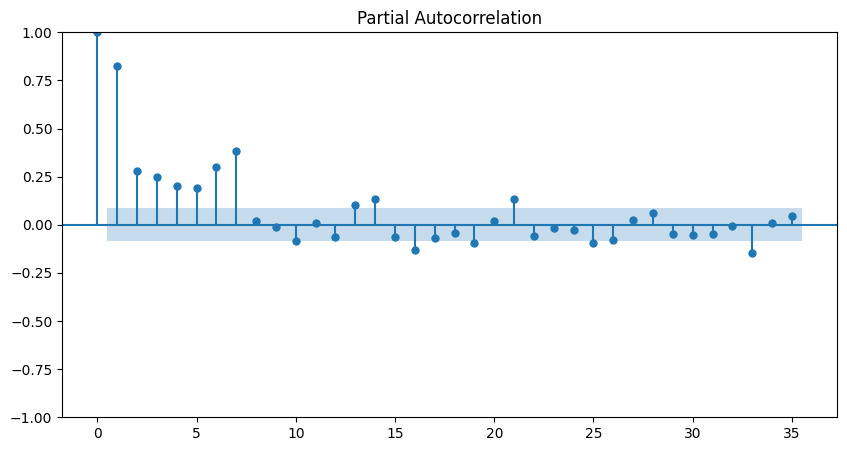

In [ ]:
fig = sm.graphics.tsa.plot_acf(train, lags=35)
plt.show()

fig = sm.graphics.tsa.plot_pacf(train, lags=35, method="ywm")
plt.show()


### 7.3 Ajuste de un ARIMA

Para el repaso no buscaremos exhaustivamente el mejor modelo posible.

Ajustaremos un modelo sencillo y evaluaremos su capacidad predictiva fuera de muestra.

> En una aplicación real compararíamos múltiples especificaciones, analizaríamos residuos y consideraríamos explícitamente patrones estacionales.


In [ ]:
modelo_arima = ARIMA(train, order=(2, 0, 2)).fit()

print(modelo_arima.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:           total_viajes   No. Observations:                  516
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -2549.297
Date:                Fri, 14 Aug 2026   AIC                           5110.594
Time:                        01:31:37   BIC                           5136.071
Sample:                    01-01-2025   HQIC                          5120.578
                         - 05-31-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        330.2623     53.853      6.133      0.000     224.713     435.812
ar.L1          0.7588      0.256      2.961      0.003       0.257       1.261
ar.L2          0.2363      0.255      0.928      0.3

In [ ]:
forecast_arima = modelo_arima.forecast(steps=h)

mae = mean_absolute_error(test, forecast_arima)
rmse = np.sqrt(mean_squared_error(test, forecast_arima))

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")


MAE:  25.47
RMSE: 32.60


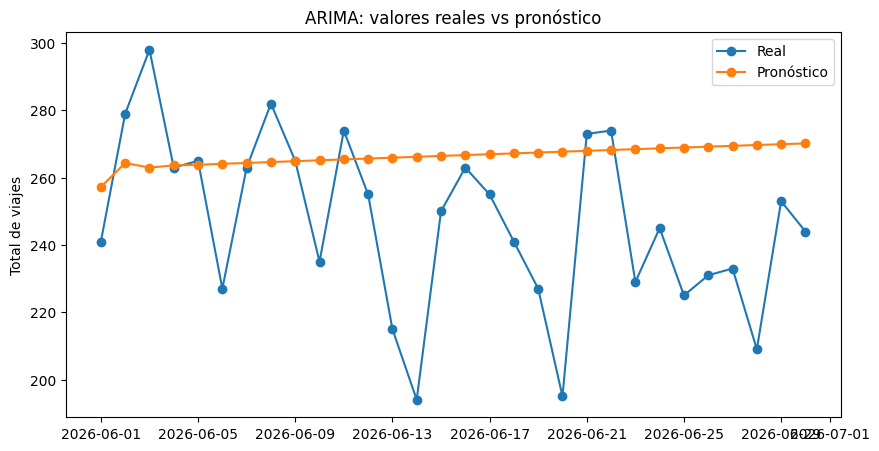

In [ ]:
plt.plot(test.index, test, marker="o", label="Real")
plt.plot(test.index, forecast_arima, marker="o", label="Pronóstico")
plt.legend()
plt.ylabel("Total de viajes")
plt.title("ARIMA: valores reales vs pronóstico")
plt.show()


El pronóstico converge rápidamente hacia un nivel promedio y no reproduce la variabilidad ni el patrón recurrente observado en la serie.

Dado que el PACF muestra un Lag a una semana, vamos a usar todos los últimos siete días para explicar "hoy"

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:           total_viajes   No. Observations:                  516
Model:                 ARIMA(7, 1, 7)   Log Likelihood               -2457.089
Date:                Fri, 14 Aug 2026   AIC                           4944.179
Time:                        01:35:09   BIC                           5007.841
Sample:                    01-01-2025   HQIC                          4969.128
                         - 05-31-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9388      0.078    -12.073      0.000      -1.091      -0.786
ar.L2         -0.9366      0.075    -12.512      0.000      -1.083      -0.790
ar.L3         -0.9549      0.074    -12.929      0.0

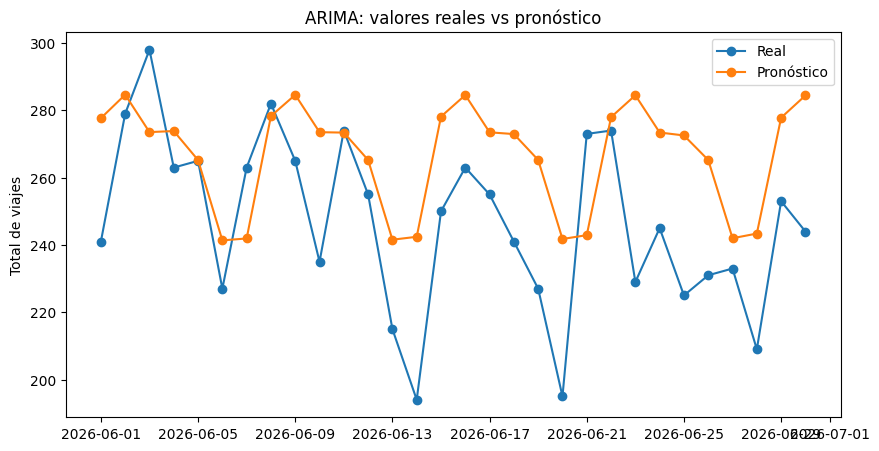

In [ ]:
modelo_arima_v2 = ARIMA(train, order=(7, 1, 7)).fit()

print(modelo_arima_v2.summary())

forecast_arima_v2 = modelo_arima_v2.forecast(steps=h)
plt.plot(test.index, test, marker="o", label="Real")
plt.plot(test.index, forecast_arima_v2, marker="o", label="Pronóstico")
plt.legend()
plt.ylabel("Total de viajes")
plt.title("ARIMA: valores reales vs pronóstico")
plt.show()




El modelo ARIMA permite capturar relaciones temporales a partir de la propia historia de la serie, combinando componentes autorregresivos, diferenciación y medias móviles. Sin embargo, cuando existe un patrón que se repite de manera sistemática cada cierto número de períodos —por ejemplo, una estacionalidad semanal— un ARIMA no estacional puede quedarse corto.

En estos casos podemos utilizar **SARIMA**, una extensión de ARIMA que incorpora explícitamente una componente estacional. Esto permite modelar no solo la dependencia entre períodos consecutivos, sino también la relación entre observaciones separadas por una frecuencia regular, como 7 días en una serie diaria con comportamiento semanal.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


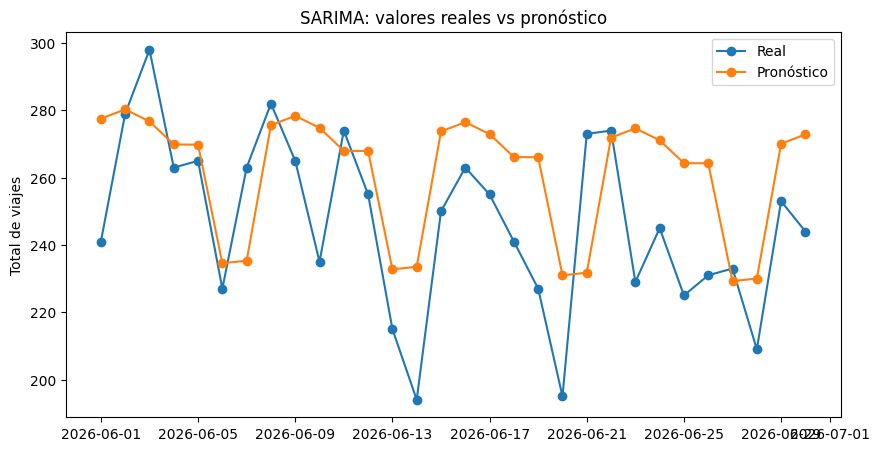

In [ ]:
modelo_sarima = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7)
).fit()

forecast_sarima = modelo_sarima.forecast(steps=len(test))

plt.plot(test.index, test, marker="o", label="Real")
plt.plot(test.index, forecast_sarima, marker="o", label="Pronóstico")

plt.legend()
plt.ylabel("Total de viajes")
plt.title("SARIMA: valores reales vs pronóstico")
plt.show()

In [ ]:
print(modelo_sarima.summary())

                                     SARIMAX Results                                     
Dep. Variable:                      total_viajes   No. Observations:                  516
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -2459.036
Date:                           Fri, 14 Aug 2026   AIC                           4928.072
Time:                                   01:37:26   BIC                           4949.303
Sample:                               01-01-2025   HQIC                          4936.392
                                    - 05-31-2026                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9961      0.004    227.585      0.000       0.987       1.005
ma.L1         -0.8043      0.027    -29.857

In [ ]:
mae_arima = mean_absolute_error(test, forecast_arima)
mae_arima_v2 = mean_absolute_error(test, forecast_arima_v2)
mae_sarima = mean_absolute_error(test, forecast_sarima)

print("MAE ARIMA:", mae_arima)
print("MAE ARIMA:", mae_arima_v2)
print("MAE SARIMA:", mae_sarima)

MAE ARIMA: 25.472656257259292
MAE ARIMA: 25.150854901043864
MAE SARIMA: 21.851729399671992


### Para discutir

- ¿Por qué Train/Test debe respetar el orden temporal?
- ¿Qué patrón observas en la serie?
- ¿El ARIMA sencillo logra capturarlo completamente?
- ¿Qué mejorarías antes de llevar este modelo a producción?
- ¿Qué diferencia existe entre explicar una variable y pronosticar una serie?


### Y si nos ponemos creativos --> Regresión + Serie de tiempo = SARIMAX

In [ ]:
serie_completa = (
    serie_diaria
    .sort_values("fecha")
    .set_index("fecha")
)

y = serie_completa["total_viajes"]

X = serie_completa[
    [
        "temperatura_promedio_c",
    ]
]

h = 30

y_train = y.iloc[:-h]
y_test = y.iloc[-h:]

X_train = X.iloc[:-h]
X_test = X.iloc[-h:]

In [ ]:
modelo_sarimax = SARIMAX(
    y_train,
    exog=X_train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7)
).fit()

print(modelo_sarimax.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                      total_viajes   No. Observations:                  516
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -2438.729
Date:                           Fri, 14 Aug 2026   AIC                           4889.457
Time:                                   01:39:15   BIC                           4914.934
Sample:                               01-01-2025   HQIC                          4899.441
                                    - 05-31-2026                                         
Covariance Type:                             opg                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
temperatura_promedio_c    11.0421      1.019     10.835      0.000       9.045      13.040
ar.L1  

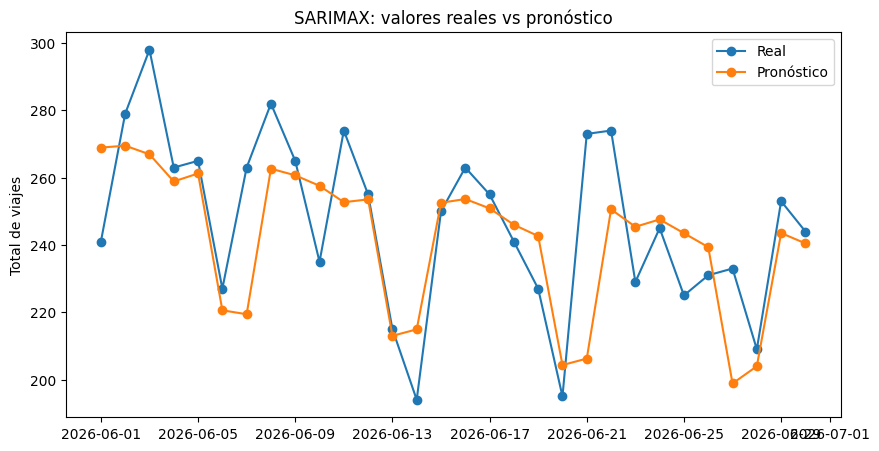

In [ ]:
forecast_sarimax = modelo_sarimax.forecast(
    steps=h,
    exog=X_test
)

plt.plot(test.index, test, marker="o", label="Real")
plt.plot(test.index, forecast_sarimax, marker="o", label="Pronóstico")

plt.legend()
plt.ylabel("Total de viajes")
plt.title("SARIMAX: valores reales vs pronóstico")
plt.show()

In [ ]:
mae_sarimax = mean_absolute_error(y_test, forecast_sarimax)
print(mae_sarimax)


15.081941334953257


### Para trabajar

Probemos otros valores de SARIMAX: Esto nos ayudará a eventualmente mejorar el modelo, y bajar la carga que está compensando actualmente ARIMA vs S_ARIMA

(1,0,0)x(1,0,0,7)

(1,0,1)x(1,0,0,7)

(1,0,0)x(1,0,1,7)

---

# 8. Tareita

### Situación

CityBike quiere mejorar el uso del servicio durante días de lluvia.

### Tu tarea

1. Formula una pregunta analítica concreta.
2. Define la variable objetivo.
3. Decide qué subconjunto de datos utilizarías.
4. Elige una técnica vista durante la clase.
5. Justifica por qué esa técnica es apropiada.
6. Ejecuta un análisis breve.
7. Escribe una conclusión de **máximo tres líneas** para un gerente comercial.



In [ ]:
# Tu análisis comienza aquí


